# Controlled Fraud Drift and Candidate Model Demonstration

**Objective:** simulate feature drift and a learnable change in the fraud-label relationship, detect the input shift, train an isolated candidate, compare it with active V2, and make a review-only recommendation.

This is an **academic simulation**, not bank retraining. Labels are generated by a disclosed toy rule and are **not verified fraud outcomes**. The frozen PaySim `isFraud` target is not loaded. V2 remains active; this notebook never approves, promotes, deploys, or replaces a model.

## 1. Concepts and safeguards

- **Feature drift:** input distributions change. A fixed weighted sampling rule emphasizes high-amount and transfer rows without editing feature values.
- **Concept drift:** the input/label relationship changes. The synthetic target is an XOR of a training-only amount cutoff and `type_TRANSFER`. This controlled toy rule is learnable by trees and is not real fraud behavior.
- V2 metadata supplies the ordered 34 predictors. `event_id` and `step` remain audit/split fields; `isFraud` is the synthetic target and never a feature.
- Source windows are chronological and disjoint. Candidate fitting uses training rows; validation supports early stopping and threshold choice. Test labels are created only after both are complete.
- The existing detector, Phase 11 trainer/evaluator, V2 model, and V2 threshold are read-only inputs. Simulation outputs use unique per-run folders.

## 2. Environment and repository discovery

The root is found relative to the notebook's current directory, so this works from the repository root or `notebooks/`. Missing dependencies are reported; none are installed.

In [1]:
from pathlib import Path
import hashlib, importlib.util, json, os, sys, uuid
from datetime import datetime, timezone

PROJECT_ROOT = next((p.resolve() for p in (Path.cwd(), *Path.cwd().resolve().parents)
    if (p / "src/retraining/v2_trainer.py").is_file() and (p / "models/model_v2_metadata.json").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the notebook from the repository root or notebooks directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
required = ("numpy", "pandas", "pyarrow", "xgboost", "sklearn", "matplotlib")
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError(f"Required environment packages are missing: {missing}; nothing was installed.")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Markdown, display
from xgboost import XGBClassifier
from src.drift.drift_detector import detect_feature_drift, detect_overall_drift, validate_drift_inputs
from src.retraining import v2_config, v2_evaluator, v2_trainer
from src.retraining.active_model import resolve_active_model
from src.orchestrator.config import RUNS_ROOT
from src.orchestrator.eligibility import evaluate_retraining_eligibility
from src.orchestrator.label_adapter import get_label_readiness_summary
print("Repository:", PROJECT_ROOT)
print("Available dependencies:", ", ".join(required))

INFO:fraud_api:Model V2 loaded. 34 expected features. Classification threshold=0.53


Repository: D:\fraud-detection-system\fraud-detection-system
Available dependencies: numpy, pandas, pyarrow, xgboost, sklearn, matplotlib


## 3. Read-only V2 baseline and real eligibility

Capture fixed V2 file hashes, resolve the active bundle, confirm the threshold and exact feature order, and read the real label/eligibility summaries. These values explain why simulated labels cannot authorize real retraining.

In [2]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def save_json_create(path, value):
    with Path(path).open("x", encoding="utf-8") as stream:
        json.dump(value, stream, indent=2, allow_nan=False)
        stream.write("\n")

FIXED_V2 = {"model": PROJECT_ROOT/"models/xgboost_model_v2.json",
            "metadata": PROJECT_ROOT/"models/model_v2_metadata.json",
            "threshold": PROJECT_ROOT/"models/model_v2_threshold.json"}
if any(not p.is_file() for p in FIXED_V2.values()):
    raise FileNotFoundError("One or more fixed V2 artifacts are missing.")
V2_HASHES_BEFORE = {k: sha256_file(p) for k,p in FIXED_V2.items()}
BUNDLE = resolve_active_model(project_root=PROJECT_ROOT)
if BUNDLE.model_version != "V2":
    raise RuntimeError(f"Expected active V2, resolver selected {BUNDLE.model_version!r}.")
V2_META = json.loads(FIXED_V2["metadata"].read_text(encoding="utf-8"))
V2_THRESHOLD = float(json.loads(FIXED_V2["threshold"].read_text(encoding="utf-8"))["selected_threshold"])
FEATURES = list(V2_META["feature_names"])
TARGET, AUDIT = "isFraud", ["event_id", "step"]
EXPECTED = AUDIT + FEATURES + [TARGET]
if len(FEATURES) != 34 or len(set(FEATURES)) != 34 or FEATURES != list(BUNDLE.feature_names):
    raise ValueError("V2 ordered 34-feature contract is invalid or inconsistent.")
if {TARGET, *AUDIT}.intersection(FEATURES) or V2_THRESHOLD != BUNDLE.threshold:
    raise ValueError("V2 feature/threshold safeguards failed.")
V2_MODEL = XGBClassifier()
V2_MODEL.load_model(str(BUNDLE.model_path))
if list(V2_MODEL.get_booster().feature_names) != FEATURES:
    raise ValueError("Loaded V2 feature order differs from metadata.")

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex
REPORT_ROOT = PROJECT_ROOT/"reports/drift_simulation"
MODEL_ROOT = PROJECT_ROOT/"models/drift_simulation"
RUN_DIR, CANDIDATE_DIR = REPORT_ROOT/RUN_ID, MODEL_ROOT/RUN_ID
REPORT_ROOT.mkdir(parents=True, exist_ok=True); MODEL_ROOT.mkdir(parents=True, exist_ok=True)
RUN_DIR.mkdir(exist_ok=False); CANDIDATE_DIR.mkdir(exist_ok=False)
FIG_DIR = RUN_DIR/"figures"; FIG_DIR.mkdir(exist_ok=False)
if any(PROJECT_ROOT not in p.resolve().parents for p in (RUN_DIR,CANDIDATE_DIR,FIG_DIR)):
    raise ValueError("Simulation output path escaped the repository root.")
real_runs_before = sorted(p.name for p in RUNS_ROOT.iterdir() if p.is_dir()) if RUNS_ROOT.is_dir() else []
REAL_LABELS = get_label_readiness_summary()
REAL_ELIGIBILITY = evaluate_retraining_eligibility()
save_json_create(RUN_DIR/"v2_artifact_baseline.json", {
    "run_id": RUN_ID, "active_version": BUNDLE.model_version, "active_source": BUNDLE.source,
    "active_artifact": str(BUNDLE.model_path.relative_to(PROJECT_ROOT)), "threshold": V2_THRESHOLD,
    "features": FEATURES, "fixed_v2_sha256_before": V2_HASHES_BEFORE,
    "active_bundle_sha256_before": dict(BUNDLE.artifact_sha256)})
display(Markdown(f"**Active model:** {BUNDLE.model_version} · **Threshold:** {V2_THRESHOLD:.4f} · **Features:** {len(FEATURES)}"))
display(Markdown(f"**Real eligibility:** `{REAL_ELIGIBILITY.get('decision_status','UNKNOWN')}` · **Genuine labels:** {REAL_LABELS.get('genuinely_verified_labels','unknown')} · **Strict readiness:** {REAL_LABELS.get('strict_retraining_ready', False)}"))
for reason in REAL_ELIGIBILITY.get("reasons", []): print("Eligibility blocker:", reason)
for reason in REAL_LABELS.get("readiness_reasons", []): print("Label evidence:", reason)
print("Simulation run:", RUN_ID)

**Active model:** V2 · **Threshold:** 0.5300 · **Features:** 34

**Real eligibility:** `BLOCKED` · **Genuine labels:** 0 · **Strict readiness:** False

Eligibility blocker: Feature drift is detected; verified labels and all readiness gates are required.
Eligibility blocker: No trusted label source is configured.
Eligibility blocker: Trusted-source authorization is not configured.
Eligibility blocker: No resolved, matched, non-synthetic trusted_verified labels are available.
Eligibility blocker: Label or prediction conflicts are present.
Eligibility blocker: Phase 9 PaySim labels are simulated and cannot satisfy genuine-label readiness.
Eligibility blocker: Existing lifecycle readiness requires event_id matching; Stage 2 records use transaction_id and no event_id mapping is established.
Eligibility blocker: Insufficient genuinely verified labels: 0 available; 100 required by the configured academic demonstration floor.
Eligibility blocker: The existing strict label-readiness gate is not satisfied.
Eligibility blocker: Label matching is not confirmed on the lifecycle-required event_id key.
Eligibility blocker: Label or prediction confli

## 4. Bounded chronological source sample

Read Parquet in Arrow batches and project only `event_id`, `step`, and the 34 predictors; the historical `isFraud` column is not loaded. A fixed-seed reservoir sample draws from the V2 metadata's train, validation, and test step windows.

In [3]:
SEED = 20261030
DATA_PATH = v2_config.V2_DATASET_PATH
SPLIT = V2_META["train_validation_test_strategy"]
TRAIN_END, VALID_END = int(SPLIT["train_end_step"]), int(SPLIT["validation_end_step"])
TEST_END = int(SPLIT.get("test_end_step", 743))
SOURCE_COLS = AUDIT + FEATURES
CAPS = {"train": 100_000, "validation": 40_000, "test": 60_000}
seen = dict.fromkeys(CAPS, 0); reservoirs = dict.fromkeys(CAPS)
rngs = {name: np.random.default_rng(SEED+i) for i,name in enumerate(CAPS)}
parquet = pq.ParquetFile(DATA_PATH)
if parquet.schema.names != EXPECTED:
    raise ValueError("Frozen V2 dataset columns differ from the Phase 11 contract.")
for batch in parquet.iter_batches(batch_size=100_000, columns=SOURCE_COLS, use_threads=True):
    frame = batch.to_pandas(); step = frame.step
    masks = {"train": step <= TRAIN_END,
        "validation": (step > TRAIN_END) & (step <= VALID_END),
        "test": (step > VALID_END) & (step <= TEST_END)}
    for name, mask in masks.items():
        part = frame.loc[mask, SOURCE_COLS]
        if part.empty: continue
        seen[name] += len(part)
        part = part.assign(_priority=rngs[name].random(len(part)))
        combined = part if reservoirs[name] is None else pd.concat([reservoirs[name],part],ignore_index=True)
        reservoirs[name] = combined.nsmallest(CAPS[name],"_priority").reset_index(drop=True)
POOLS = {name: frame.drop(columns="_priority").sort_values(["step","event_id"],kind="stable").reset_index(drop=True)
         for name,frame in reservoirs.items() if frame is not None}
for name, frame in POOLS.items():
    if len(frame) < 5_000 or not frame.event_id.is_unique:
        raise ValueError(f"Insufficient or duplicate source rows in {name} window.")
    if not all(pd.api.types.is_numeric_dtype(frame[f]) for f in FEATURES):
        raise ValueError(f"Non-numeric feature in {name} window.")
display(pd.DataFrame([{"partition":n,"source_window_rows":seen[n],"sampled_rows":len(f),
    "first_step":int(f.step.min()),"last_step":int(f.step.max())} for n,f in POOLS.items()]))
print("Source isFraud labels loaded: NO")

,partition,source_window_rows,sampled_rows,first_step,last_step
0,train,5015193,100000,1,422
1,validation,185387,40000,423,565
2,test,181624,60000,566,743


Source isFraud labels loaded: NO


## 5. Generate feature shift and the synthetic concept

Unique rows are sampled without replacement inside disjoint time windows, with fixed weights for high amounts and transaction type. Feature values are unchanged. The toy concept is a training-derived amount threshold XOR transfer indicator. Test features are prepared now, but test labels remain absent.

In [4]:
AMOUNT_Q = 0.80
AMOUNT_CUTOFF = float(POOLS["train"].amount.quantile(AMOUNT_Q))
WEIGHTS = {"base":1.0,"high_amount":5.0,"transfer":6.0,"cash_out":2.0}
SIZES = {"train":30_000,"validation":12_000,"test":20_000}

def probabilities(pool):
    high = (pool.amount.to_numpy(float) >= AMOUNT_CUTOFF).astype(float)
    transfer = pool.type_TRANSFER.to_numpy(float)
    cashout = pool.type_CASH_OUT.to_numpy(float)
    w = WEIGHTS["base"] + WEIGHTS["high_amount"]*high + WEIGHTS["transfer"]*transfer + WEIGHTS["cash_out"]*cashout
    if not np.isfinite(w).all() or (w <= 0).any(): raise ValueError("Invalid sampling weights.")
    return w/w.sum()

def draw(name, seed):
    pool, n = POOLS[name], SIZES[name]
    if n > len(pool): raise ValueError(f"Not enough {name} rows for sampling without replacement.")
    ix = np.random.default_rng(seed).choice(len(pool), size=n, replace=False, p=probabilities(pool))
    chosen = pool.iloc[ix].copy().reset_index(drop=True)
    source_ids = set(chosen.event_id.astype(str))
    if len(source_ids) != n: raise ValueError("Source sample repeats rows.")
    chosen["event_id"] = [f"SIM-{RUN_ID}-{name}-{i:06d}" for i in range(n)]
    return chosen[SOURCE_COLS], source_ids

def label_concept(frame):
    high = frame.amount.to_numpy(float) >= AMOUNT_CUTOFF
    transfer = frame.type_TRANSFER.to_numpy(float) >= 0.5
    result = frame.copy(); result[TARGET] = np.logical_xor(high,transfer).astype("int8")
    result = result[EXPECTED]
    if set(result[TARGET].unique()) != {0,1}: raise ValueError("Simulation partition lacks a class.")
    return result

reference = POOLS["train"][SOURCE_COLS].copy()
train_x, train_sources = draw("train", SEED+1001)
validation_x, validation_sources = draw("validation", SEED+1002)
test_x, test_sources = draw("test", SEED+1003)
if (train_sources & validation_sources) or (train_sources & test_sources) or (validation_sources & test_sources):
    raise ValueError("Source IDs overlap chronological partitions.")
train_sim = label_concept(train_x); validation_sim = label_concept(validation_x)
if TARGET in test_x: raise ValueError("Test labels must stay unavailable before training.")
for frame in (train_sim,validation_sim): v2_trainer.validate_v2_dataset(frame)
SIM_CONFIG = {"run_id":RUN_ID,"seed":SEED,"data_sha256":sha256_file(DATA_PATH),
    "source_target_loaded":False,"temporal_bounds":{"train_end":TRAIN_END,"validation_end":VALID_END,"test_end":TEST_END},
    "source_window_rows":seen,"sampled_pool_rows":{k:len(v) for k,v in POOLS.items()},"simulation_rows":SIZES,
    "sampling":"unique weighted sampling without replacement","weights":WEIGHTS,
    "concept_rule":"simulated isFraud = (amount >= training-source 80th percentile) XOR type_TRANSFER",
    "amount_cutoff":AMOUNT_CUTOFF,"features":FEATURES,"audit_columns":AUDIT,"target":TARGET,
    "labels":"synthetic, not verified ground truth","test_labels_created_before_training":False}
save_json_create(RUN_DIR/"simulation_configuration.json",SIM_CONFIG)
save_json_create(RUN_DIR/"split_summary.json",{
    "split_method":"chronological V2 step windows with disjoint source IDs",
    "train":{"rows":len(train_sim),"step":[int(train_sim.step.min()),int(train_sim.step.max())],"simulated_positive":int(train_sim[TARGET].sum())},
    "validation":{"rows":len(validation_sim),"step":[int(validation_sim.step.min()),int(validation_sim.step.max())],"simulated_positive":int(validation_sim[TARGET].sum())},
    "test":{"rows":len(test_x),"step":[int(test_x.step.min()),int(test_x.step.max())],"labels_created":False},
    "source_ids_disjoint":True,"target_in_features":False})
display(pd.DataFrame([{"partition":n,"rows":len(f),"simulated_positive_rate":float(f[TARGET].mean())}
    for n,f in (("train",train_sim),("validation",validation_sim))]+[{"partition":"test","rows":len(test_x),"simulated_positive_rate":"not created"}]))
print("Test labels available before training:", TARGET in test_x)

,partition,rows,simulated_positive_rate
0,train,30000,0.336533
1,validation,12000,0.323333
2,test,20000,not created


Test labels available before training: False


## 6. Detect and visualize feature drift

Reuse the Phase 8 detector: PSI and KS/proportion tests with Benjamini–Hochberg correction, followed by its configured overall drift-rate threshold. Only reference/current features are passed; no target is present.

,feature_name,feature_type,reference_count,recent_count,reference_nan_rate,recent_nan_rate,reference_mean,recent_mean,reference_std,recent_std,psi,ks_statistic,ks_p_value,proportion_test_statistic,proportion_test_p_value,adjusted_p_value,drift_detected,drift_reason
22,sender_hours_since_prev_txn,continuous,126,58,0.99874,0.99710,1.386349e+02,4.138966e+02,9.318863e+01,1.406431e+02,5.671679,0.786535,4.156827e-25,NaN,NaN,5.888838e-25,True,PSI significant (5.6717 >= 0.2); KS test signi...
23,dest_hours_since_prev_txn,continuous,57524,14321,0.42476,0.28395,1.979301e+01,2.125130e+02,2.759891e+01,1.006845e+02,3.929387,0.817103,0.000000e+00,NaN,NaN,0.000000e+00,True,PSI significant (3.9294 >= 0.2); KS test signi...
26,dest_txn_count_last_168h,continuous,100000,20000,0.00000,0.00000,3.970680e+00,2.297500e-01,5.740373e+00,5.009640e-01,3.915866,0.468370,0.000000e+00,NaN,NaN,0.000000e+00,True,PSI significant (3.9159 >= 0.2); KS test signi...
25,dest_txn_count_last_24h,continuous,100000,20000,0.00000,0.00000,1.291540e+00,3.375000e-02,2.937837e+00,1.865769e-01,2.592711,0.384390,0.000000e+00,NaN,NaN,0.000000e+00,True,PSI significant (2.5927 >= 0.2); KS test signi...
28,dest_amount_sum_last_168h,continuous,100000,20000,0.00000,0.00000,1.045078e+06,6.925356e+04,2.333136e+06,3.616818e+05,1.415217,0.413860,0.000000e+00,NaN,NaN,0.000000e+00,True,PSI significant (1.4152 >= 0.2); KS test signi...
27,dest_amount_sum_last_24h,continuous,100000,20000,0.00000,0.00000,3.609483e+05,1.304567e+04,1.601940e+06,2.475256e+05,1.257795,0.384390,0.000000e+00,NaN,NaN,0.000000e+00,True,PSI significant (1.2578 >= 0.2); KS test signi...
20,amount_vs_sender_hist_mean,continuous,126,58,0.99874,0.99710,2.421520e+01,4.466672e+01,1.405891e+02,1.529149e+02,0.451529,0.201697,6.659903e-02,NaN,NaN,7.304409e-02,True,PSI significant (0.4515 >= 0.2)
1,amount,continuous,100000,20000,0.00000,0.00000,1.752287e+05,3.164055e+05,6.347983e+05,7.336167e+05,0.280473,0.221710,0.000000e+00,NaN,NaN,0.000000e+00,True,PSI significant (0.2805 >= 0.2); KS test signi...
2,log_amount,continuous,100000,20000,0.00000,0.00000,1.082980e+01,1.164911e+01,1.813357e+00,1.686133e+00,0.280473,0.221710,0.000000e+00,NaN,NaN,0.000000e+00,True,PSI significant (0.2805 >= 0.2); KS test signi...
32,type_PAYMENT,binary,100000,20000,0.00000,0.00000,3.360700e-01,1.475500e-01,4.723632e-01,3.546533e-01,0.202299,NaN,NaN,52.878544,0.000000e+00,0.000000e+00,True,PSI significant (0.2023 >= 0.2); proportion te...


**DRIFT DETECTED** · 31/34 features (91.2%)

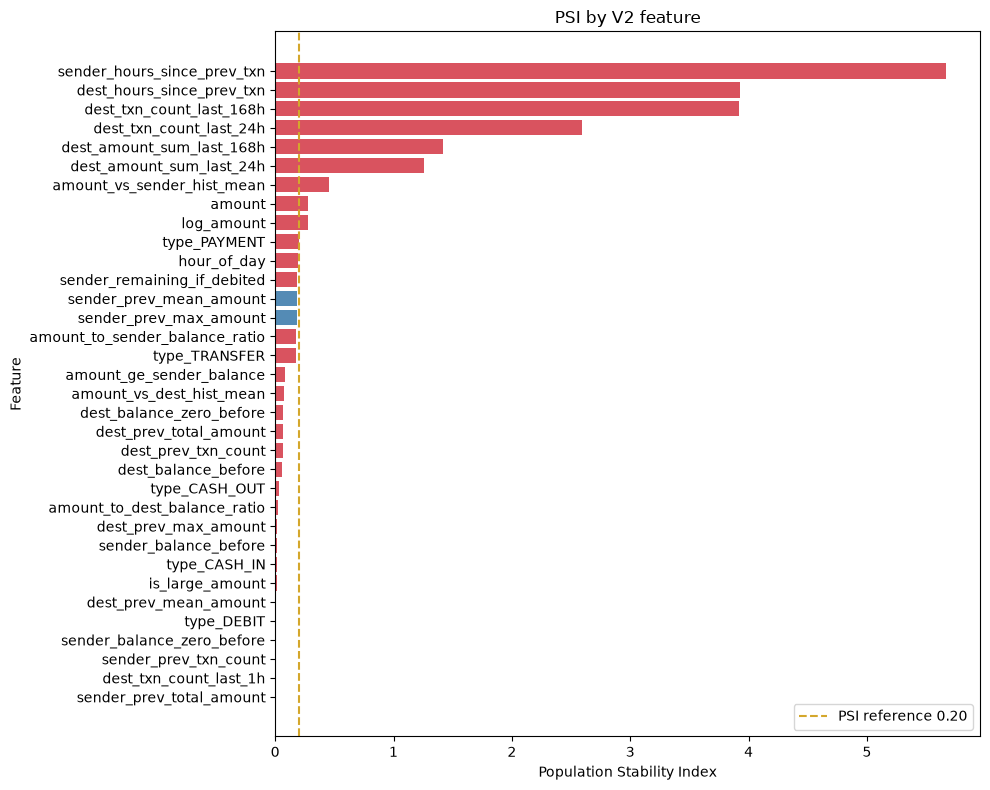

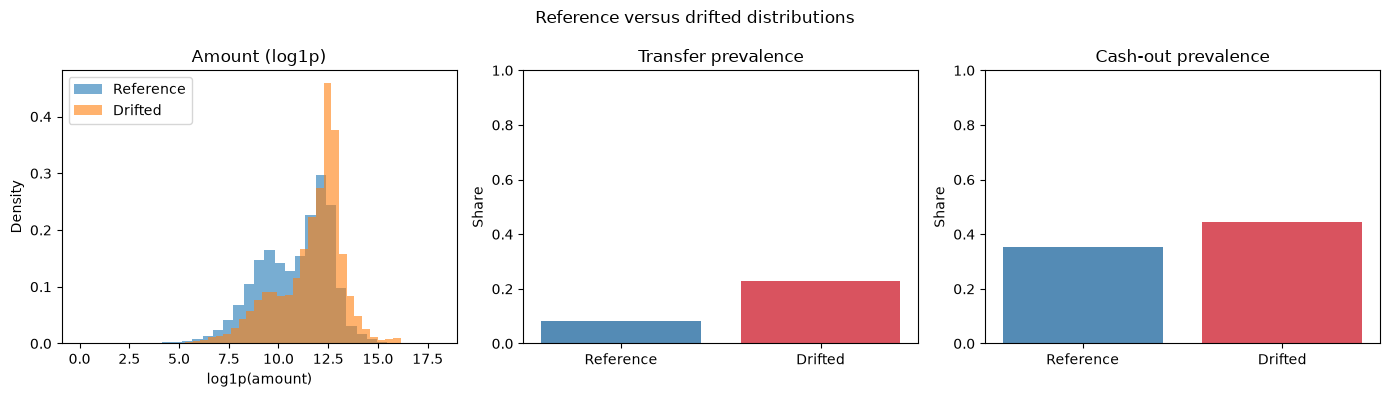

Affected features: ['hour_of_day', 'amount', 'log_amount', 'is_large_amount', 'amount_to_sender_balance_ratio', 'amount_ge_sender_balance', 'sender_remaining_if_debited', 'amount_to_dest_balance_ratio', 'sender_balance_before', 'sender_balance_zero_before', 'dest_balance_before', 'dest_balance_zero_before', 'sender_prev_txn_count', 'dest_prev_txn_count', 'dest_prev_total_amount', 'dest_prev_mean_amount', 'dest_prev_max_amount', 'amount_vs_sender_hist_mean', 'amount_vs_dest_hist_mean', 'sender_hours_since_prev_txn', 'dest_hours_since_prev_txn', 'dest_txn_count_last_1h', 'dest_txn_count_last_24h', 'dest_txn_count_last_168h', 'dest_amount_sum_last_24h', 'dest_amount_sum_last_168h', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [5]:
monitor = test_x[SOURCE_COLS].copy()
checks = validate_drift_inputs(reference, monitor, FEATURES)
if not all(checks.values()): raise ValueError(f"Drift detector input checks failed: {checks}")
drift_table = detect_feature_drift(reference[FEATURES],monitor[FEATURES],FEATURES)
overall = detect_overall_drift(drift_table)
drift_report = {"run_id":RUN_ID,"execution_type":"SIMULATION_ONLY",
    "method":"PSI plus KS for continuous / two-proportion for binary; BH correction",
    "reference_rows":len(reference),"monitoring_rows":len(monitor),
    "reference_step":[int(reference.step.min()),int(reference.step.max())],
    "monitoring_step":[int(monitor.step.min()),int(monitor.step.max())],
    "features_tested":int(overall["features_tested"]),"features_drifted":int(overall["features_drifted"]),
    "drift_rate":float(overall["drift_rate"]),"threshold":float(overall["drift_rate_threshold"]),
    "drift_detected":bool(overall["overall_drift_detected"]),
    "affected_features":json.loads(drift_table.to_json(orient="records")),
    "limitations":["Historical PaySim-derived features; not new real transactions.","Drift is not causal evidence of performance change."]}
drift_table.to_csv(RUN_DIR/"feature_drift_results.csv",index=False,mode="x")
save_json_create(RUN_DIR/"drift_report.json",drift_report)
display(drift_table.sort_values(["drift_detected","psi"],ascending=[False,False]))
display(Markdown(f"**{'DRIFT DETECTED' if drift_report['drift_detected'] else 'NO DRIFT DETECTED'}** · {overall['features_drifted']}/{overall['features_tested']} features ({overall['drift_rate']:.1%})"))
fig,ax=plt.subplots(figsize=(10,8)); plotted=drift_table.sort_values("psi")
ax.barh(plotted.feature_name,plotted.psi.fillna(0),color=["#d9535f" if v else "#548bb5" for v in plotted.drift_detected])
ax.axvline(.20,color="#d4a72c",linestyle="--",label="PSI reference 0.20")
ax.set(title="PSI by V2 feature",xlabel="Population Stability Index",ylabel="Feature"); ax.legend(); fig.tight_layout()
with (FIG_DIR/"psi_by_feature.png").open("xb") as f: fig.savefig(f,format="png",dpi=150)
plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].hist(np.log1p(reference.amount),bins=35,density=True,alpha=.6,label="Reference")
axes[0].hist(np.log1p(monitor.amount),bins=35,density=True,alpha=.6,label="Drifted")
axes[0].set(title="Amount (log1p)",xlabel="log1p(amount)",ylabel="Density"); axes[0].legend()
for ax,feature,title in zip(axes[1:],("type_TRANSFER","type_CASH_OUT"),("Transfer prevalence","Cash-out prevalence")):
    ax.bar(["Reference","Drifted"],[reference[feature].mean(),monitor[feature].mean()],color=["#548bb5","#d9535f"])
    ax.set(title=title,ylabel="Share",ylim=(0,1))
fig.suptitle("Reference versus drifted distributions"); fig.tight_layout()
with (FIG_DIR/"reference_vs_drifted.png").open("xb") as f: fig.savefig(f,format="png",dpi=150)
plt.show()
print("Affected features:",drift_table.loc[drift_table.drift_detected,"feature_name"].tolist())

## 7. Real eligibility remains separate and blocked

Generated labels never enter the real label store. They do not establish verified ground truth or a transaction-to-event ID mapping. The real eligibility result is read-only and cannot be overridden by this demonstration.

In [6]:
print("Real retraining decision:",REAL_ELIGIBILITY.get("decision_status","UNKNOWN"))
print("Strict verified-label readiness:",REAL_LABELS.get("strict_retraining_ready",False))
print("Verified label count:",REAL_LABELS.get("genuinely_verified_labels","unknown"))
print("Label match key:",REAL_LABELS.get("matching_key","UNKNOWN"),"; lifecycle key:",REAL_LABELS.get("lifecycle_required_matching_key","UNKNOWN"))
for reason in REAL_LABELS.get("readiness_reasons",[]): print("Blocked by:",reason)
print("No labels were submitted, registered, replayed, or changed.")

Real retraining decision: BLOCKED
Strict verified-label readiness: False
Verified label count: 0
Label match key: transaction_id ; lifecycle key: event_id
Blocked by: No trusted label source is configured.
Blocked by: Trusted-source authorization is not configured.
Blocked by: No resolved, matched, non-synthetic trusted_verified labels are available.
Blocked by: Label or prediction conflicts are present.
Blocked by: Phase 9 PaySim labels are simulated and cannot satisfy genuine-label readiness.
Blocked by: Existing lifecycle readiness requires event_id matching; Stage 2 records use transaction_id and no event_id mapping is established.
No labels were submitted, registered, replayed, or changed.


## 8. Train the isolated candidate with train/validation only

Reuse `v2_trainer.train_v2` and V2 metadata parameters. Training data is used for fitting; validation supports Phase 11 early stopping and threshold selection. Test labels still do not exist. Candidate artifacts are kept under this unique simulation run.

In [7]:
CANDIDATE_PATH=CANDIDATE_DIR/"simulation_candidate.json"
META_PATH=CANDIDATE_DIR/"metadata.json"
THRESHOLD_PATH=CANDIDATE_DIR/"threshold.json"
TRAIN_REPORT_PATH=CANDIDATE_DIR/"training_report.json"
base_params=V2_META.get("xgboost_parameters")
if not isinstance(base_params,dict) or not base_params: raise ValueError("V2 metadata has no training parameters.")
class_weight=v2_trainer.compute_training_scale_pos_weight(train_sim[TARGET])
params=v2_trainer.build_v2_params(base_params,class_weight,SEED)
params["n_jobs"]=max(1,min(4,os.cpu_count() or 1)); params.setdefault("eval_metric","aucpr")
candidate,training_seconds=v2_trainer.train_v2(train_sim,validation_sim,params)
if CANDIDATE_PATH.exists(): raise FileExistsError(CANDIDATE_PATH)
candidate.save_model(str(CANDIDATE_PATH))
if not CANDIDATE_PATH.is_file() or CANDIDATE_PATH.resolve().parent!=CANDIDATE_DIR.resolve(): raise RuntimeError("Candidate was not isolated.")
threshold_grid=v2_evaluator.threshold_grid_search(candidate,validation_sim)
candidate_threshold,validation_choice=v2_evaluator.select_threshold(threshold_grid)
if not 0<candidate_threshold<1: raise ValueError("Invalid validation-selected threshold.")
threshold_record={"run_id":RUN_ID,"selected_threshold":float(candidate_threshold),
    "method":"maximum F1 on synthetic validation; Phase 11 tie-breaks precision then lower threshold",
    "validation_rows":len(validation_sim),"validation_metrics":{k:float(validation_choice[k]) for k in ("precision","recall","f1")},
    "test_used":False,"label_provenance":"SIMULATED_NOTEBOOK_CONCEPT_RULE"}
metadata_record={"run_id":RUN_ID,"model_version":"SIMULATION-"+RUN_ID,"model_type":"XGBClassifier binary:logistic",
    "simulation_only":True,"label_provenance":"Generated XOR rule; not verified outcomes.",
    "feature_count":len(FEATURES),"feature_names":FEATURES,"audit_columns":AUDIT,"target":TARGET,
    "source_dataset_sha256":SIM_CONFIG["data_sha256"],"training_rows":len(train_sim),"validation_rows":len(validation_sim),
    "concept_rule":SIM_CONFIG["concept_rule"],"parameters":params,"seed":SEED,
    "training_seconds":float(training_seconds),"best_iteration":int(getattr(candidate,"best_iteration",params["n_estimators"]-1)),
    "candidate_sha256":sha256_file(CANDIDATE_PATH)}
training_report={"run_id":RUN_ID,"status":"COMPLETED_SIMULATION_ONLY","train_rows":len(train_sim),
    "validation_rows":len(validation_sim),"test_data_accessed":False,"test_labels_created":False,
    "threshold_selection":threshold_record,"candidate_sha256":metadata_record["candidate_sha256"]}
save_json_create(META_PATH,metadata_record); save_json_create(THRESHOLD_PATH,threshold_record); save_json_create(TRAIN_REPORT_PATH,training_report)
print(f"Candidate training time: {training_seconds:.2f}s; selected validation threshold: {candidate_threshold:.4f}")
print("Candidate saved:",CANDIDATE_PATH.relative_to(PROJECT_ROOT))
print("Test labels still absent:",TARGET not in test_x.columns)

Candidate training time: 2.92s; selected validation threshold: 0.3200
Candidate saved: models\drift_simulation\20261030T061641Z_b7ac7b9ec4ec4536ac46697435aa39f2\simulation_candidate.json
Test labels still absent: True


## 9. Fair V2 versus candidate test evaluation

After fitting and validation threshold selection, generate the held-out synthetic test labels. Both models use the same test feature matrix, event rows, and labels. V2 retains its resolver threshold; the candidate uses its validation-selected threshold.

In [8]:
if TARGET in test_x.columns: raise ValueError("Test labels appeared before final evaluation.")
test_sim=test_x.copy()
test_sim[TARGET]=label_concept(test_x)[TARGET].to_numpy(dtype="int8")
test_sim=test_sim[EXPECTED]
if test_sim[TARGET].nunique()!=2: raise ValueError("Test cohort must contain both generated classes.")
shared_v2=test_sim.loc[:,FEATURES]; shared_candidate=test_sim.loc[:,FEATURES]
if not shared_v2.equals(shared_candidate): raise ValueError("Models do not share identical test features.")
test_fingerprint=hashlib.sha256(pd.util.hash_pandas_object(shared_v2,index=False).to_numpy().tobytes()).hexdigest()
event_fingerprint=hashlib.sha256("\n".join(test_sim.event_id.astype(str)).encode()).hexdigest()
v2_metrics=v2_evaluator.evaluate_split(V2_MODEL,test_sim,V2_THRESHOLD)
candidate_metrics=v2_evaluator.evaluate_split(candidate,test_sim,candidate_threshold)
score_keys=("precision","recall","f1","pr_auc","roc_auc")
count_keys=("tn","fp","fn","tp","rows")
comparison=pd.DataFrame([
    {"model":"Active V2","threshold":V2_THRESHOLD,**v2_metrics},
    {"model":"Simulation candidate","threshold":candidate_threshold,**candidate_metrics},
]).rename(columns={"rows":"samples"})
display(comparison[["model","threshold",*score_keys,"tn","fp","fn","tp","samples"]])
comparison.to_csv(RUN_DIR/"v2_vs_candidate_comparison.csv",index=False,mode="x")
evaluation={"run_id":RUN_ID,"status":"COMPLETED","execution_type":"SIMULATION_ONLY",
    "test_rows":len(test_sim),"test_simulated_positives":int(test_sim[TARGET].sum()),
    "test_feature_fingerprint":test_fingerprint,"test_event_id_fingerprint":event_fingerprint,
    "identical_test_rows":True,"test_used_for_fit_or_threshold":False,"labels_simulated":True,
    "thresholds":{"V2":V2_THRESHOLD,"candidate_validation_selected":float(candidate_threshold)},
    "metrics":{"V2":v2_metrics,"candidate":candidate_metrics}}
save_json_create(RUN_DIR/"candidate_evaluation_metrics.json",evaluation)
print("Same test feature fingerprint:",test_fingerprint)
print("FP V2/candidate:",v2_metrics["fp"],candidate_metrics["fp"],"| FN:",v2_metrics["fn"],candidate_metrics["fn"])

,model,threshold,precision,recall,f1,pr_auc,roc_auc,tn,fp,fn,tp,samples
0,Active V2,0.53,0.549505,0.033278,0.062756,0.363262,0.509522,13147,182,6449,222,20000
1,Simulation candidate,0.32,0.998952,0.999850,0.999401,0.999987,0.999994,13322,7,1,6670,20000


Same test feature fingerprint: 9dd555f7b241302fbaaee10fd04900a33532dec8ba634e0ca58fdb4fa47698f6
FP V2/candidate: 182 7 | FN: 6449 1


## 10. Metric and confusion-matrix visualizations

All charts use the same generated test cohort. Higher is better for the plotted scores; confusion matrices show raw counts.

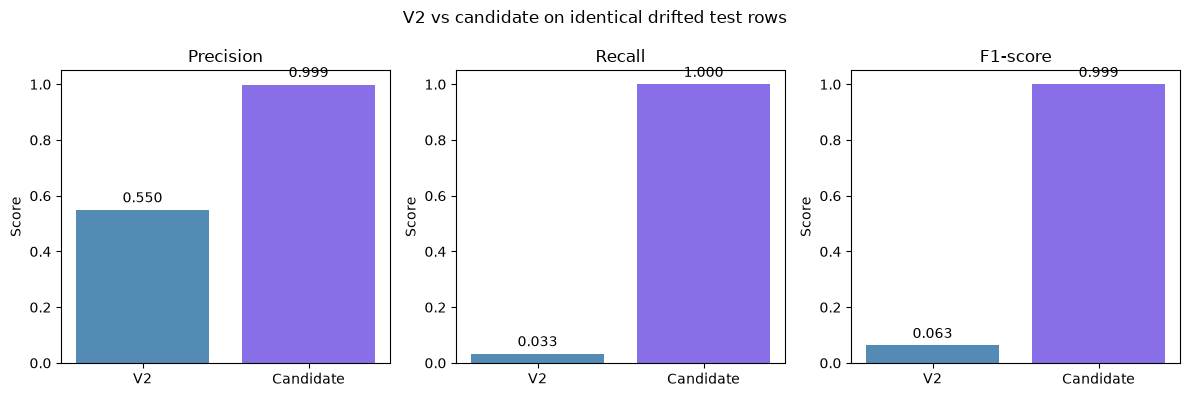

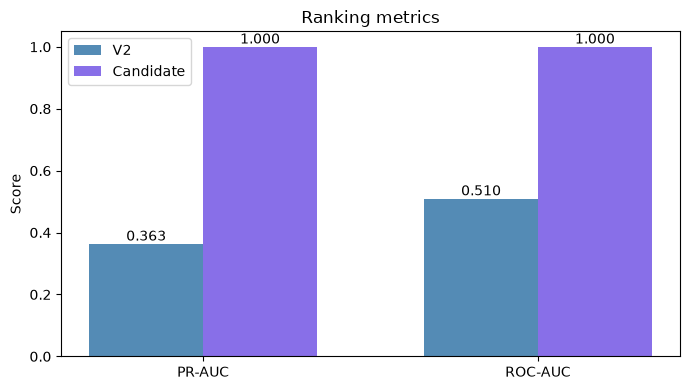

C:\Users\MYSHA MUBASHIR\AppData\Local\Temp\ipykernel_20424\3165668684.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.colorbar(image,ax=axes,shrink=.8,label="Rows"); fig.tight_layout()


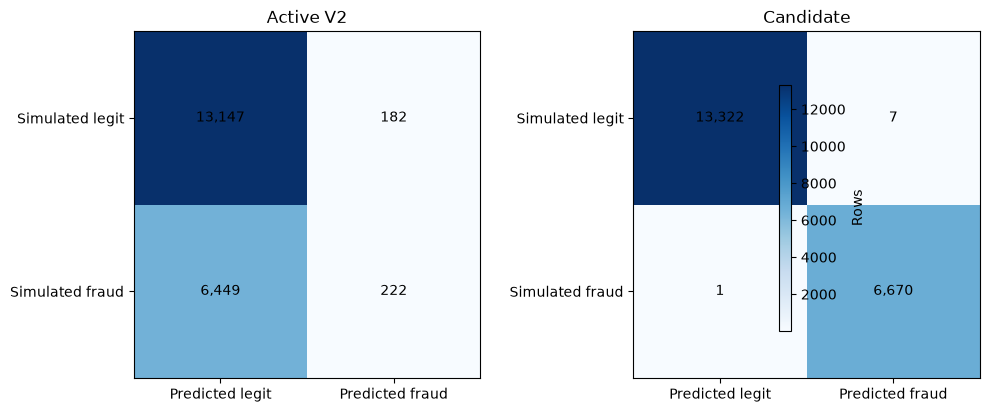

Saved charts: reports\drift_simulation\20261030T061641Z_b7ac7b9ec4ec4536ac46697435aa39f2\figures


In [9]:
fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,key,title in zip(axes,("precision","recall","f1"),("Precision","Recall","F1-score")):
    bars=ax.bar(["V2","Candidate"],[v2_metrics[key],candidate_metrics[key]],color=["#548bb5","#886fe8"])
    ax.set(title=title,ylabel="Score",ylim=(0,1.05)); ax.bar_label(bars,fmt="%.3f",padding=3)
fig.suptitle("V2 vs candidate on identical drifted test rows"); fig.tight_layout()
with (FIG_DIR/"precision_recall_f1.png").open("xb") as f: fig.savefig(f,format="png",dpi=150)
plt.show()
fig,ax=plt.subplots(figsize=(7,4)); x=np.arange(2); width=.34
v=[v2_metrics["pr_auc"],v2_metrics["roc_auc"]]; c=[candidate_metrics["pr_auc"],candidate_metrics["roc_auc"]]
a=ax.bar(x-width/2,v,width,label="V2",color="#548bb5"); b=ax.bar(x+width/2,c,width,label="Candidate",color="#886fe8")
ax.set_xticks(x,["PR-AUC","ROC-AUC"]); ax.set_ylim(0,1.05); ax.set_ylabel("Score"); ax.legend(); ax.set_title("Ranking metrics")
ax.bar_label(a,fmt="%.3f"); ax.bar_label(b,fmt="%.3f"); fig.tight_layout()
with (FIG_DIR/"auc_metrics.png").open("xb") as f: fig.savefig(f,format="png",dpi=150)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,name,m in zip(axes,("Active V2","Candidate"),(v2_metrics,candidate_metrics)):
    matrix=np.array([[m["tn"],m["fp"]],[m["fn"],m["tp"]]])
    image=ax.imshow(matrix,cmap="Blues"); ax.set_xticks([0,1],["Predicted legit","Predicted fraud"])
    ax.set_yticks([0,1],["Simulated legit","Simulated fraud"]); ax.set_title(name)
    for (i,j),value in np.ndenumerate(matrix): ax.text(j,i,f"{value:,}",ha="center",va="center")
fig.colorbar(image,ax=axes,shrink=.8,label="Rows"); fig.tight_layout()
with (FIG_DIR/"confusion_matrices.png").open("xb") as f: fig.savefig(f,format="png",dpi=150)
plt.show()
print("Saved charts:",FIG_DIR.relative_to(PROJECT_ROOT))

## 11. Explicit recommendation for human review

Recommend only when evaluation completed, required metrics are finite/valid, candidate PR-AUC and F1 are strictly higher, recall is not lower, and false negatives do not increase. Failed criteria are listed verbatim; no threshold is weakened after looking at test results.

In [10]:
def valid_scores(metrics):
    return all(metrics.get(k) is not None and np.isfinite(metrics[k]) and 0<=metrics[k]<=1 for k in score_keys)
def valid_counts(metrics):
    return all(isinstance(metrics.get(k),(int,np.integer)) and metrics[k]>=0 for k in count_keys)
valid_metrics=(evaluation["status"]=="COMPLETED" and valid_scores(v2_metrics) and valid_scores(candidate_metrics)
    and valid_counts(v2_metrics) and valid_counts(candidate_metrics)
    and sum(v2_metrics[k] for k in ("tn","fp","fn","tp"))==len(test_sim)
    and sum(candidate_metrics[k] for k in ("tn","fp","fn","tp"))==len(test_sim))
criteria={"evaluation_completed":evaluation["status"]=="COMPLETED",
    "required_metrics_finite_and_valid":bool(valid_metrics),
    "candidate_pr_auc_better":bool(valid_metrics and candidate_metrics["pr_auc"]>v2_metrics["pr_auc"]),
    "candidate_f1_better":bool(valid_metrics and candidate_metrics["f1"]>v2_metrics["f1"]),
    "candidate_recall_not_worse":bool(valid_metrics and candidate_metrics["recall"]>=v2_metrics["recall"]),
    "candidate_false_negatives_not_increased":bool(valid_metrics and candidate_metrics["fn"]<=v2_metrics["fn"])}
reasons=[]
reason_map={"evaluation_completed":"Evaluation did not complete successfully.",
 "required_metrics_finite_and_valid":"Required metrics are missing, non-finite, or invalid.",
 "candidate_pr_auc_better":"Candidate PR-AUC is not strictly better than V2.",
 "candidate_f1_better":"Candidate F1 is not strictly better than V2.",
 "candidate_recall_not_worse":"Candidate recall is lower than V2.",
 "candidate_false_negatives_not_increased":"Candidate false negatives exceed V2."}
for key,passed in criteria.items():
    if not passed: reasons.append(reason_map[key])
recommendation="CANDIDATE_RECOMMENDED_FOR_REVIEW" if all(criteria.values()) else "CANDIDATE_NOT_RECOMMENDED"
if all(criteria.values()): reasons=["Candidate passed the predefined gates on identical held-out synthetic observations.",
    "This is for human review only, not production approval or deployment."]
recommendation_report={"run_id":RUN_ID,"recommendation":recommendation,"scope":"controlled simulation; human review only",
    "criteria":criteria,"reasons":reasons,"metrics":{"V2":v2_metrics,"candidate":candidate_metrics},
    "test_feature_fingerprint":test_fingerprint,"active_model":"V2","automatic_promotion":False,
    "real_verified_labels_used":False,"execution_type":"SIMULATION_ONLY"}
save_json_create(RUN_DIR/"final_recommendation_report.json",recommendation_report)
display(Markdown("# "+recommendation))
for reason in reasons: print("-",reason)
display(pd.DataFrame([{"criterion":k,"passed":v} for k,v in criteria.items()]))

# CANDIDATE_RECOMMENDED_FOR_REVIEW

- Candidate passed the predefined gates on identical held-out synthetic observations.
- This is for human review only, not production approval or deployment.


,criterion,passed
0,evaluation_completed,True
1,required_metrics_finite_and_valid,True
2,candidate_pr_auc_better,True
3,candidate_f1_better,True
4,candidate_recall_not_worse,True
5,candidate_false_negatives_not_increased,True


## 12. Final safety audit and summary

Verify fixed V2 hashes, active resolution, candidate separation, and unchanged real orchestrator run history. The workflow ends at the recommendation; no promotion path is called.

In [11]:
V2_HASHES_AFTER={k:sha256_file(p) for k,p in FIXED_V2.items()}
HASH_CHECKS={k:V2_HASHES_AFTER[k]==V2_HASHES_BEFORE[k] for k in FIXED_V2}
BUNDLE_AFTER=resolve_active_model(project_root=PROJECT_ROOT)
ACTIVE_UNCHANGED=(BUNDLE_AFTER.model_version=="V2" and BUNDLE_AFTER.model_path.resolve()==BUNDLE.model_path.resolve()
    and BUNDLE_AFTER.threshold==BUNDLE.threshold)
real_runs_after=sorted(p.name for p in RUNS_ROOT.iterdir() if p.is_dir()) if RUNS_ROOT.is_dir() else []
REAL_RUNS_UNCHANGED=real_runs_after==real_runs_before
CANDIDATE_SEPARATE=(CANDIDATE_PATH.is_file() and CANDIDATE_PATH.resolve().is_relative_to(MODEL_ROOT.resolve())
    and CANDIDATE_PATH.resolve()!=BUNDLE_AFTER.model_path.resolve())
if not all(HASH_CHECKS.values()) or not ACTIVE_UNCHANGED or not REAL_RUNS_UNCHANGED or not CANDIDATE_SEPARATE:
    raise RuntimeError("Simulation safety audit failed; inspect the recorded checks.")
summary={"run_id":RUN_ID,"execution_type":"SIMULATION_ONLY","drift_detected":drift_report["drift_detected"],
    "drifted_features":drift_report["features_drifted"],"tested_features":drift_report["features_tested"],
    "real_orchestrator_decision":REAL_ELIGIBILITY.get("decision_status","UNKNOWN"),
    "v2_metrics":v2_metrics,"candidate_metrics":candidate_metrics,"recommendation":recommendation,
    "active_model":"V2","v2_hashes_unchanged":HASH_CHECKS,"candidate_saved_separately":CANDIDATE_SEPARATE,
    "real_orchestrator_runs_unchanged":REAL_RUNS_UNCHANGED,"automatic_promotion":"NO","real_verified_labels_used":"NO",
    "candidate_path":CANDIDATE_PATH.relative_to(PROJECT_ROOT).as_posix(),
    "report_directory":RUN_DIR.relative_to(PROJECT_ROOT).as_posix()}
save_json_create(RUN_DIR/"final_demonstration_summary.json",summary)
display(pd.DataFrame([
 {"Safety check":"Active model remains V2","result":"PASS" if ACTIVE_UNCHANGED else "FAIL"},
 {"Safety check":"Fixed V2 artifact hashes unchanged","result":"PASS" if all(HASH_CHECKS.values()) else "FAIL"},
 {"Safety check":"Candidate saved separately","result":"PASS" if CANDIDATE_SEPARATE else "FAIL"},
 {"Safety check":"Real orchestrator run history unchanged","result":"PASS" if REAL_RUNS_UNCHANGED else "FAIL"},
 {"Safety check":"Automatic promotion / verified labels","result":"NO / NO"}]))
print("Recommendation:",recommendation)
print("V2:",{k:v2_metrics[k] for k in (*score_keys,"fp","fn")})
print("Candidate:",{k:candidate_metrics[k] for k in (*score_keys,"fp","fn")})
print("Candidate:",CANDIDATE_PATH.relative_to(PROJECT_ROOT)); print("Reports:",RUN_DIR.relative_to(PROJECT_ROOT))

,Safety check,result
0,Active model remains V2,PASS
1,Fixed V2 artifact hashes unchanged,PASS
2,Candidate saved separately,PASS
3,Real orchestrator run history unchanged,PASS
4,Automatic promotion / verified labels,NO / NO


Recommendation: CANDIDATE_RECOMMENDED_FOR_REVIEW
V2: {'precision': 0.5495049504950495, 'recall': 0.033278369060110925, 'f1': 0.06275618374558303, 'pr_auc': 0.3632622804244034, 'roc_auc': 0.5095218717781675, 'fp': 182, 'fn': 6449}
Candidate: {'precision': 0.998951624981279, 'recall': 0.9998500974366662, 'f1': 0.9994006592747977, 'pr_auc': 0.9999872335774793, 'roc_auc': 0.999993713291852, 'fp': 7, 'fn': 1}
Candidate: models\drift_simulation\20261030T061641Z_b7ac7b9ec4ec4536ac46697435aa39f2\simulation_candidate.json
Reports: reports\drift_simulation\20261030T061641Z_b7ac7b9ec4ec4536ac46697435aa39f2


## Limitations

The input features are sampled from previously used PaySim rows, though source windows remain separate and test observations are unseen by candidate fitting. Weighted sampling creates controlled covariate drift; the synthetic XOR rule creates a learnable concept change. These are not new independent bank transactions or verified outcomes. A recommendation applies only to this constructed simulation and is not production readiness.